# Úkol č. 2 - regrese

  * **Deadline je do 4. 12. 2022, 23:59:59**, pokud odevzdáte úkol do 11. 12. 2022, 23:59:59, budete penalizování -4 body, pozdější odevzdání je bez bodu.
  * V rámci tohoto úkolu se musíte vypořádat s problematikou regrese a hledání optimálních hyperparametrů.
    
> **Úkoly jsou zadány tak, aby Vám daly prostor pro invenci. Vymyslet _jak přesně_ budete úkol řešit, je důležitou součástí zadání a originalita či nápaditost bude také hodnocena!**

Využívejte buňky typu `Markdown` k vysvětlování Vašeho postupu. Za nepřehlednost budeme strhávat body.

## Zdroj dat

  * Zdrojem dat je soubor `LifeExpectancyData.csv` (originál zde: https://www.kaggle.com/kumarajarshi/life-expectancy-who).
  * Popis datasetu najdete na uvedené stránce s originálem datasetu.
  * Cílová (vysvětlovaná) proměnná se jmenuje `Life expectancy `.

## Pokyny k vypracování

**Body zadání**, za jejichž (poctivé) vypracování získáte **16 bodů**:
  * Odeberte z datasetu datové body, u kterých neznáte vysvětlovanou proměnnou.
  * Rozdělte data na vhodné podmnožiny, které Vám poslouží pro trénování, porovnávání modelů a následnou predikci výkonnosti finálního modelu.
  * Proveďte základní průzkum dat a svá pozorování diskutujte. Na jeho základě adekvátně reagujte na problematické věci v datech (chybějící hodnoty, atd.) a vysvětlete motivaci k provedeným krokům.
  * Aplikujte lineární a hřebenovou regresi a výsledky řádně vyhodnoťte:
      * K měření chyby použijte MAE (mean absolute error) a RMSE (root mean squared error).

  * Zkoumejte, jak byste mohli modely vylepšit:
      * Experimentujte s tvorbou nových příznaků (na základě těch dostupných).
      * Experimentujte se standardizací/normalizací dat.
      * Vyberte si hyperparametry modelů k ladění a najděte jejich nejlepší hodnoty.
      * Získané výsledky vždy řádně okomentujte.
    
  * Použijte i jiné modely (alespoň jeden) probírané v předmětu BI-ML1 či i jiné, pokud víte, jak fungují.
  * Nakonec vyberte nejlepší model (vzhledem k RMSE) a odhadněte, jakou RMSE a MAE můžete očekávat na nových datech, která jste doposud neměli k dispozici.

## Poznámky k odevzdání

  * Řiďte se pokyny ze stránky https://courses.fit.cvut.cz/BI-ML1/homeworks/index.html.
  * Opravující Vám ve výjimečných případech může umožnit úkol dodělat či opravit a získat tak další body. První verze je ale stěžejní a má hlavní vliv na hodnocení.

In [1]:
### odtud už je to Vaše

<b>Start of project</b> 

Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import metrics, datasets
from sklearn.model_selection import train_test_split

Load data from <b>LifeExpectancyData.csv</b>

In [3]:
dataset = pd.read_csv("LifeExpectancyData.csv")

display(dataset.shape)
display(dataset.isnull().sum())

(2938, 22)

Country                              0
Year                                 0
Status                               0
Life expectancy                     10
Adult Mortality                     10
infant deaths                        0
Alcohol                            194
percentage expenditure               0
Hepatitis B                        553
Measles                              0
 BMI                                34
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
 HIV/AIDS                            0
GDP                                448
Population                         652
 thinness  1-19 years               34
 thinness 5-9 years                 34
Income composition of resources    167
Schooling                          163
dtype: int64

Look at the dataset itself

In [4]:
display(dataset)

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2933,Zimbabwe,2004,Developing,44.3,723.0,27,4.36,0.000000,68.0,31,...,67.0,7.13,65.0,33.6,454.366654,12777511.0,9.4,9.4,0.407,9.2
2934,Zimbabwe,2003,Developing,44.5,715.0,26,4.06,0.000000,7.0,998,...,7.0,6.52,68.0,36.7,453.351155,12633897.0,9.8,9.9,0.418,9.5
2935,Zimbabwe,2002,Developing,44.8,73.0,25,4.43,0.000000,73.0,304,...,73.0,6.53,71.0,39.8,57.348340,125525.0,1.2,1.3,0.427,10.0
2936,Zimbabwe,2001,Developing,45.3,686.0,25,1.72,0.000000,76.0,529,...,76.0,6.16,75.0,42.1,548.587312,12366165.0,1.6,1.7,0.427,9.8


Remove the rows without <b>Life expectancy</b>

In [5]:
dataset = dataset[dataset['Life expectancy '].notna()]
display(dataset.isnull().sum())

Country                              0
Year                                 0
Status                               0
Life expectancy                      0
Adult Mortality                      0
infant deaths                        0
Alcohol                            193
percentage expenditure               0
Hepatitis B                        553
Measles                              0
 BMI                                32
under-five deaths                    0
Polio                               19
Total expenditure                  226
Diphtheria                          19
 HIV/AIDS                            0
GDP                                443
Population                         644
 thinness  1-19 years               32
 thinness 5-9 years                 32
Income composition of resources    160
Schooling                          160
dtype: int64

Take a look if the values in the dataset are realistic and corespond to reality

In [6]:
dataset.describe().round(2)

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,BMI,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
count,2928.00,2928.00,2928.00,2928.00,2735.00,2928.00,2375.00,2928.00,2896.00,2928.00,2909.00,2702.00,2909.00,2928.00,2485.00,2.284000e+03,2896.00,2896.00,2768.00,2768.00
mean,2007.50,69.22,164.80,30.41,4.61,740.32,80.96,2427.86,38.24,42.18,82.55,5.93,82.32,1.75,7494.21,1.276454e+07,4.85,4.88,0.63,12.00
std,4.61,9.52,124.29,118.11,4.05,1990.93,25.02,11485.97,19.96,160.70,23.42,2.48,23.71,5.09,14282.25,6.103765e+07,4.42,4.51,0.21,3.35
min,2000.00,36.30,1.00,0.00,0.01,0.00,1.00,0.00,1.00,0.00,3.00,0.37,2.00,0.10,1.68,3.400000e+01,0.10,0.10,0.00,0.00
25%,2003.75,63.10,74.00,0.00,0.90,4.85,77.00,0.00,19.30,0.00,78.00,4.26,78.00,0.10,463.85,1.966738e+05,1.60,1.58,0.49,10.10
50%,2007.50,72.10,144.00,3.00,3.77,65.61,92.00,17.00,43.35,4.00,93.00,5.75,93.00,0.10,1764.97,1.391756e+06,3.30,3.40,0.68,12.30
75%,2011.25,75.70,228.00,22.00,7.72,442.61,97.00,362.25,56.10,28.00,97.00,7.49,97.00,0.80,5932.90,7.426746e+06,7.20,7.20,0.78,14.30
max,2015.00,89.00,723.00,1800.00,17.87,19479.91,99.00,212183.00,77.60,2500.00,99.00,17.60,99.00,50.60,119172.74,1.293859e+09,27.70,28.60,0.95,20.70


<b>Column by colmun analysis of most of the variables</b>

Country: seems fine, just some unusual names (Lao, Bolivia, DPRK)
Year: seems fine, also evenly split
Life expectancy: seems fine
Adult Mortality: lowest avaliable, somewhat controvesial sources claim a value of 40, anyhting less is very unlikely, maximum seems fine
Infant deaths: decreasing in recent years, maximum would be low 100s based on the year the data was collected, a value of 0 is also unrealistic 
Alcohol: seems fine, <i>even if 0.01 liters per year is probably not the actual unofficial value in any country </i>
Hepatitis B: seems fine
Measles: it looks like the number shows total cases that year in the country, so dividing by population would make sense, however lots of countries do not have population data, keeping the column still makes sense since it separates countries with outbreaks from those without
BMI: the values are correct, but it's overweight rate as % of population :) (https://gamapserver.who.int/gho/interactive_charts/ncd/risk_factors/overweight/atlas.html)
Polio: seems fine
Total expenditure: seems fine 
Diphteria: seems fine
HIV/AIDS: seems fine
GDP: minimums are too low, this column also has most of the misplaced decimal points and programatically it's diffcult to tell which numbers here are wrong since the difference can be large  
Thinness: seems fine
Income composition: seems fine, commonly known as is HDI
Percentage expenditure: this one is filled almost randomly, closest would be usd/person spent on healthcare but even that is not too consistent







Throw out some of the uneaslitic values

In [7]:
dataset.loc[(dataset["Adult Mortality"] < 40), 'Adult Mortality'] = np.NAN
dataset.loc[( (dataset["infant deaths"] < 1 ) | (dataset["infant deaths"] > 200 ) ), 'infant deaths'] = np.NAN
dataset.loc[(dataset["GDP"] < 150), 'GDP'] = np.NAN

Rename 2 columns to have a more accurate name

In [8]:
dataset.rename(columns={' BMI ': 'Overweight rate in %', 'Income composition of resources': 'HDI'}, inplace=True)

In [9]:
dataset.describe().round(2)

,Year,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,Overweight rate in %,under-five deaths,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,HDI,Schooling
count,2928.00,2928.00,2462.00,2004.00,2735.00,2928.00,2375.00,2928.00,2896.00,2928.00,2909.00,2702.00,2909.00,2928.00,2248.00,2.284000e+03,2896.00,2896.00,2768.00,2768.00
mean,2007.50,69.22,192.64,21.31,4.61,740.32,80.96,2427.86,38.24,42.18,82.55,5.93,82.32,1.75,8276.71,1.276454e+07,4.85,4.88,0.63,12.00
std,4.61,9.52,116.12,29.82,4.05,1990.93,25.02,11485.97,19.96,160.70,23.42,2.48,23.71,5.09,14801.16,6.103765e+07,4.42,4.51,0.21,3.35
min,2000.00,36.30,41.00,1.00,0.01,0.00,1.00,0.00,1.00,0.00,3.00,0.37,2.00,0.10,152.44,3.400000e+01,0.10,0.10,0.00,0.00
25%,2003.75,63.10,113.00,2.00,0.90,4.85,77.00,0.00,19.30,0.00,78.00,4.26,78.00,0.10,672.63,1.966738e+05,1.60,1.58,0.49,10.10
50%,2007.50,72.10,164.00,8.00,3.77,65.61,92.00,17.00,43.35,4.00,93.00,5.75,93.00,0.10,2422.39,1.391756e+06,3.30,3.40,0.68,12.30
75%,2011.25,75.70,251.00,29.00,7.72,442.61,97.00,362.25,56.10,28.00,97.00,7.49,97.00,0.80,7187.25,7.426746e+06,7.20,7.20,0.78,14.30
max,2015.00,89.00,723.00,196.00,17.87,19479.91,99.00,212183.00,77.60,2500.00,99.00,17.60,99.00,50.60,119172.74,1.293859e+09,27.70,28.60,0.95,20.70


First see correlation matrix for an overview of which attributes are most likely to affect the result

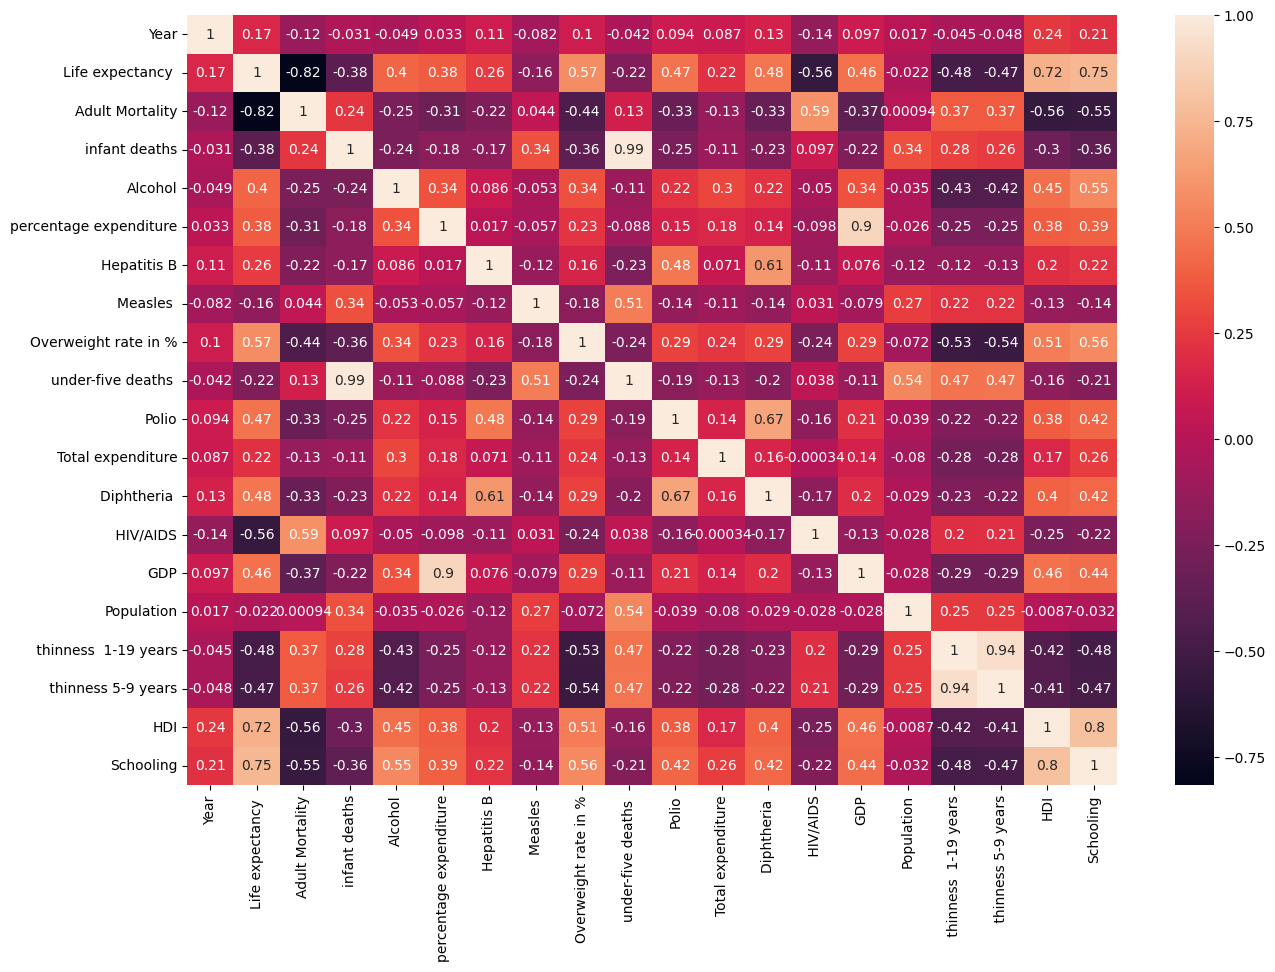

In [10]:
corr_matrix = dataset.corr()
plt.figure(figsize=(15,10))
sns.heatmap(corr_matrix, annot=True)
plt.show()

In [11]:
#drops the all the nan rows with illnesses, not used in the end, doesn't change much 
#dataset = dataset[dataset['Polio'].notna()] 
#dataset = dataset[dataset[' BMI '].notna()]

# display(dataset.isnull().sum())

<b>Population</b> has almost no effect on life expectancy while having lots of missing values

In [12]:
dataset.drop(["Population"],axis = 'columns', inplace = True)
# display(dataset.isnull().sum())

<b>percentage expenditure, thinness and under-five deaths</b> are too correlated with other columns, it's best to drop them to simplify the model

In [13]:
#drop too correlated
dataset.drop(["percentage expenditure"],axis = 'columns', inplace = True)
dataset.drop([" thinness 5-9 years"],axis = 'columns', inplace = True)
dataset.drop(["under-five deaths "],axis = 'columns', inplace = True)

In [14]:
dataset.info()
dataset.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2928 entries, 0 to 2937
Data columns (total 18 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Country                2928 non-null   object 
 1   Year                   2928 non-null   int64  
 2   Status                 2928 non-null   object 
 3   Life expectancy        2928 non-null   float64
 4   Adult Mortality        2462 non-null   float64
 5   infant deaths          2004 non-null   float64
 6   Alcohol                2735 non-null   float64
 7   Hepatitis B            2375 non-null   float64
 8   Measles                2928 non-null   int64  
 9   Overweight rate in %   2896 non-null   float64
 10  Polio                  2909 non-null   float64
 11  Total expenditure      2702 non-null   float64
 12  Diphtheria             2909 non-null   float64
 13   HIV/AIDS              2928 non-null   float64
 14  GDP                    2248 non-null   float64
 15   thi

Country                    0
Year                       0
Status                     0
Life expectancy            0
Adult Mortality          466
infant deaths            924
Alcohol                  193
Hepatitis B              553
Measles                    0
Overweight rate in %      32
Polio                     19
Total expenditure        226
Diphtheria                19
 HIV/AIDS                  0
GDP                      680
 thinness  1-19 years     32
HDI                      160
Schooling                160
dtype: int64

It would be great to make an encoding for each <b>country</b> but there are too many of them, so at least separate them into <b>continents</b>.

In [15]:
Africa= ['Algeria','Angola','Benin','Botswana','Burkina Faso','Burundi','Cabo Verde','Cameroon','Central African Republic','Chad','Comoros','Democratic Republic of the Congo','Republic of the Congo','Cote d\'Ivoire','Djibouti','Egypt','Equatorial Guinea','Eritrea','Ethiopia','Gabon','Gambia','Ghana','Guinea','Guinea-Bissau', 'Guinea Bissau','Kenya','Lesotho','Liberia','Libya','Madagascar','Malawi','Mali','Mauritania','Mauritius','Morocco','Mozambique','Namibia','Niger','Nigeria','Rwanda','Sao Tome and Principe','Senegal','Seychelles','Sierra Leone','Somalia','South Africa','South Sudan','Sudan','Swaziland','Tanzania','Togo','Tunisia','Uganda','Zambia','Zimbabwe', "Côte d'Ivoire", 'Congo']
NorthAmerica= ['Antigua and Barbuda','Bahamas','Barbados','Belize','Canada','Costa Rica','Cuba','Dominica','Dominican Republic','El Salvador','Grenada','Guatemala','Haiti','Honduras','Jamaica','Mexico','Nicaragua','Panama','Saint Kitts and Nevis','Saint Lucia','Saint Vincent and the Grenadines','Trinidad and Tobago','United States of America']
SouthAmerica =['Argentina', 'Bolivia','Brazil','Chile','Colombia','Ecuador','Guyana','Paraguay','Peru','Suriname','Uruguay','Venezuela']
Europe = ['Czechia','Albania','Andorra','Armenia','Austria','Azerbaijan','Belarus','Belgium','Bosnia and Herzegovina','Bulgaria','Croatia','Cyprus','Czech Republic','Denmark','Estonia','Finland','France','Georgia','Germany','Greece','Hungary','Iceland','Ireland','Italy','Kazakhstan','Kosovo','Latvia','Liechtenstein','Lithuania','Luxembourg','Macedonia','Malta','Moldova','Monaco','Montenegro','Netherlands','Norway','Poland','Portugal','Romania','Russia','San Marino','Serbia','Slovakia','Slovenia','Spain','Sweden','Switzerland','Turkey','Ukraine','United Kingdom','Vatican City', '']
Asia = ["Democratic People's Republic of Korea", 'Afghanistan','Armenia','Azerbaijan','Bahrain','Bangladesh','Bhutan','Brunei', 'Cambodia','China','Cyprus','Georgia','India','Indonesia','Iran (Islamic Republic of)','Iraq','Israel', 'Japan','Jordan','Kazakhstan','Kuwait','Kyrgyzstan','Laos','Lao People\'s Democratic Republic','Lebanon','Malaysia','Maldives','Mongolia','Myanmar','Nepal','North Korea','Oman','Pakistan','Palestine','Philippines','Qatar','Russia','Saudi Arabia','Singapore','South Korea','Sri Lanka','Syria','Taiwan','Tajikistan','Thailand','Timor Leste','Turkey','Turkmenistan','United Arab Emirates','Uzbekistan','Vietnam','Yemen', 'Republic of Korea']
Oceania = ['Australia','Federated Islands of Micronesia','Fiji','French Polynesia','Guam','Kiribati','Marshall Islands','Nauru','New Zealand','Paulau','Papua New Guinea','Samoa','Solomon Islands','Tonga','Tuvalu','Vanuatu', 'Micronesia (Federated States of)']


def getContinent(row):
    #python 3.10 knows match :/

    #check substring one way
    if row["Country"] in Africa:
        return "Afr"
    elif row["Country"] in NorthAmerica:
        return "NA"
    elif row["Country"] in SouthAmerica:
        return "SA"
    elif row["Country"] in Europe:
        return "Eur"
    elif row["Country"] in Asia:
        return "Asia"
    elif row["Country"] in Oceania:
        return "Oce"

    #check substring other way
    for country in Africa:
        if country in row["Country"]:
            return "Afr"
    for country in NorthAmerica:
        if country in row["Country"]:
            return "NA"
    for country in SouthAmerica:
        if country in row["Country"]:
            return "SA"
    for country in Europe:
        if country in row["Country"]:
            return "Eur"
    for country in Asia:
        if country in row["Country"]:
            return "Asia"
    for country in Oceania:
        if country in row["Country"]:
            return "Oce"

    else:
        return "Other"



In [16]:
dataset["Continent"] = dataset.apply(getContinent, axis=1)

In [17]:
dataset["Continent"].value_counts()

Afr     864
Eur     784
Asia    592
NA      336
SA      192
Oce     160
Name: Continent, dtype: int64

In [18]:
dataset

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,Hepatitis B,Measles,Overweight rate in %,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,thinness 1-19 years,HDI,Schooling,Continent
0,Afghanistan,2015,Developing,65.0,263.0,62.0,0.01,65.0,1154,19.1,6.0,8.16,65.0,0.1,584.259210,17.2,0.479,10.1,Asia
1,Afghanistan,2014,Developing,59.9,271.0,64.0,0.01,62.0,492,18.6,58.0,8.18,62.0,0.1,612.696514,17.5,0.476,10.0,Asia
2,Afghanistan,2013,Developing,59.9,268.0,66.0,0.01,64.0,430,18.1,62.0,8.13,64.0,0.1,631.744976,17.7,0.470,9.9,Asia
3,Afghanistan,2012,Developing,59.5,272.0,69.0,0.01,67.0,2787,17.6,67.0,8.52,67.0,0.1,669.959000,17.9,0.463,9.8,Asia
4,Afghanistan,2011,Developing,59.2,275.0,71.0,0.01,68.0,3013,17.2,68.0,7.87,68.0,0.1,NaN,18.2,0.454,9.5,Asia
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2933,Zimbabwe,2004,Developing,44.3,723.0,27.0,4.36,68.0,31,27.1,67.0,7.13,65.0,33.6,454.366654,9.4,0.407,9.2,Afr
2934,Zimbabwe,2003,Developing,44.5,715.0,26.0,4.06,7.0,998,26.7,7.0,6.52,68.0,36.7,453.351155,9.8,0.418,9.5,Afr
2935,Zimbabwe,2002,Developing,44.8,73.0,25.0,4.43,73.0,304,26.3,73.0,6.53,71.0,39.8,NaN,1.2,0.427,10.0,Afr
2936,Zimbabwe,2001,Developing,45.3,686.0,25.0,1.72,76.0,529,25.9,76.0,6.16,75.0,42.1,548.587312,1.6,0.427,9.8,Afr


Change Status from Object to Bool, since one hot encoding creates two identical inversed variables which may cause problems in traing phase

In [19]:
dataset.Status.value_counts()

Developing    2416
Developed      512
Name: Status, dtype: int64

In [20]:
status = {'Developed': 1,'Developing': 0}

dataset['Status'] = dataset['Status'].map(status)

Encode continent variable

In [21]:
#dummy_Status = pd.get_dummies(dataset.Status)
dummy_Continent = pd.get_dummies(dataset.Continent)


dataset = pd.concat([dataset, dummy_Continent],axis='columns')
dataset.drop(["Continent"], axis = 'columns',inplace=True)

dataset.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 2928 entries, 0 to 2937
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Country                2928 non-null   object 
 1   Year                   2928 non-null   int64  
 2   Status                 2928 non-null   int64  
 3   Life expectancy        2928 non-null   float64
 4   Adult Mortality        2462 non-null   float64
 5   infant deaths          2004 non-null   float64
 6   Alcohol                2735 non-null   float64
 7   Hepatitis B            2375 non-null   float64
 8   Measles                2928 non-null   int64  
 9   Overweight rate in %   2896 non-null   float64
 10  Polio                  2909 non-null   float64
 11  Total expenditure      2702 non-null   float64
 12  Diphtheria             2909 non-null   float64
 13   HIV/AIDS              2928 non-null   float64
 14  GDP                    2248 non-null   float64
 15   thi

Separate values for training the model into training, validation and testing

In [22]:
X = dataset.drop("Life expectancy ", axis = 1)
y = dataset["Life expectancy "]


display(X.head())
display(y.head())

,Country,Year,Status,Adult Mortality,infant deaths,Alcohol,Hepatitis B,Measles,Overweight rate in %,Polio,...,GDP,thinness 1-19 years,HDI,Schooling,Afr,Asia,Eur,NA,Oce,SA
0,Afghanistan,2015,0,263.0,62.0,0.01,65.0,1154,19.1,6.0,...,584.259210,17.2,0.479,10.1,0,1,0,0,0,0
1,Afghanistan,2014,0,271.0,64.0,0.01,62.0,492,18.6,58.0,...,612.696514,17.5,0.476,10.0,0,1,0,0,0,0
2,Afghanistan,2013,0,268.0,66.0,0.01,64.0,430,18.1,62.0,...,631.744976,17.7,0.470,9.9,0,1,0,0,0,0
3,Afghanistan,2012,0,272.0,69.0,0.01,67.0,2787,17.6,67.0,...,669.959000,17.9,0.463,9.8,0,1,0,0,0,0
4,Afghanistan,2011,0,275.0,71.0,0.01,68.0,3013,17.2,68.0,...,NaN,18.2,0.454,9.5,0,1,0,0,0,0


0    65.0
1    59.9
2    59.9
3    59.5
4    59.2
Name: Life expectancy , dtype: float64

In [23]:
random_seed = 42

Xtrain, Xval, ytrain, yval = train_test_split(dataset.drop(columns = ['Life expectancy ']), dataset['Life expectancy '], test_size=0.15, random_state=random_seed)
Xval, Xtest, yval, ytest = train_test_split(Xval, yval, test_size=0.3, random_state=random_seed)

print(f"Train size, X: {Xtrain.shape}, y: {ytrain.shape}")
print(f"Val size, X: {Xval.shape}, y: {yval.shape}")
print(f"Test size, X: {Xtest.shape}, y: {ytest.shape}")

Train size, X: (2488, 23), y: (2488,)
Val size, X: (308, 23), y: (308,)
Test size, X: (132, 23), y: (132,)


We still have missing values in the dataset, we'll try to first fill them by getting average values from the training set for each country separately and putting that value wherever necessary.
After that we do the same thing but separeted by the status of development of the country to hopefully fill in all the missing values.

In [24]:
display(dataset.isnull().sum())
display(dataset.shape)

Country                    0
Year                       0
Status                     0
Life expectancy            0
Adult Mortality          466
infant deaths            924
Alcohol                  193
Hepatitis B              553
Measles                    0
Overweight rate in %      32
Polio                     19
Total expenditure        226
Diphtheria                19
 HIV/AIDS                  0
GDP                      680
 thinness  1-19 years     32
HDI                      160
Schooling                160
Afr                        0
Asia                       0
Eur                        0
NA                         0
Oce                        0
SA                         0
dtype: int64

(2928, 24)

In [25]:
Xtrain.Country.unique()

array(['Uzbekistan', 'Burkina Faso', 'Japan', 'Sierra Leone', 'Austria',
       'Romania', 'Saint Vincent and the Grenadines', 'Egypt', 'Brazil',
       'Tajikistan', 'Kenya', 'Sao Tome and Principe', 'Solomon Islands',
       'Saudi Arabia', 'Kiribati', 'El Salvador', 'Cabo Verde',
       'Guatemala', 'Czechia', 'Eritrea', 'Timor-Leste', 'Luxembourg',
       'Barbados', 'Saint Lucia', 'Indonesia', 'Qatar', 'Panama',
       'Grenada', 'Djibouti', 'Canada', 'Yemen', 'Ethiopia', 'Gabon',
       'Zimbabwe', 'Nepal', 'Armenia',
       'Venezuela (Bolivarian Republic of)', 'Iran (Islamic Republic of)',
       'Cameroon', 'Turkey', 'Bosnia and Herzegovina', 'Iraq', 'China',
       'Nigeria', 'Turkmenistan', 'United Arab Emirates', 'Swaziland',
       'Chad', 'Estonia', 'Liberia', "Côte d'Ivoire", 'Bangladesh',
       'Niger', 'Bhutan', 'Belgium', 'Slovakia', 'Benin', 'Guinea-Bissau',
       'Belarus', 'Bolivia (Plurinational State of)',
       'Syrian Arab Republic', 'Ecuador', 'Italy', 'Pol

In [26]:
#first fill the training set 
#Country
for Country in list(Xtrain.Country.unique()):
    for col in list(Xtrain.columns)[3:]:
        Xtrain[col] = Xtrain[col].fillna(Xtrain[col].dropna().median()).round(2)

In [27]:
#Status
for Status in list(Xtrain.Status.unique()):
    for col in list(Xtrain.columns)[3:]:
        Xtrain[col] = Xtrain[col].fillna(Xtrain[col].dropna().median()).round(2)

In [28]:
Xtrain.Country.unique()

array(['Uzbekistan', 'Burkina Faso', 'Japan', 'Sierra Leone', 'Austria',
       'Romania', 'Saint Vincent and the Grenadines', 'Egypt', 'Brazil',
       'Tajikistan', 'Kenya', 'Sao Tome and Principe', 'Solomon Islands',
       'Saudi Arabia', 'Kiribati', 'El Salvador', 'Cabo Verde',
       'Guatemala', 'Czechia', 'Eritrea', 'Timor-Leste', 'Luxembourg',
       'Barbados', 'Saint Lucia', 'Indonesia', 'Qatar', 'Panama',
       'Grenada', 'Djibouti', 'Canada', 'Yemen', 'Ethiopia', 'Gabon',
       'Zimbabwe', 'Nepal', 'Armenia',
       'Venezuela (Bolivarian Republic of)', 'Iran (Islamic Republic of)',
       'Cameroon', 'Turkey', 'Bosnia and Herzegovina', 'Iraq', 'China',
       'Nigeria', 'Turkmenistan', 'United Arab Emirates', 'Swaziland',
       'Chad', 'Estonia', 'Liberia', "Côte d'Ivoire", 'Bangladesh',
       'Niger', 'Bhutan', 'Belgium', 'Slovakia', 'Benin', 'Guinea-Bissau',
       'Belarus', 'Bolivia (Plurinational State of)',
       'Syrian Arab Republic', 'Ecuador', 'Italy', 'Pol

In [29]:
#next fill the validation and test sets with averages of the already processed training data 
#Country
for Country in list(Xval.Country.unique()):
    for col in list(Xval[Country].columns)[3:]:    
        Xval[col] = Xval[col].fillna(Xtrain[col].dropna().median()).round(2)
for Country in list(Xtest.Country.unique()):
    for col in list(Xtest[Country].columns)[3:]:
        Xtest[col] = Xtest[col].fillna(Xtrain[col].dropna().median()).round(2)

KeyError: "Lao People's Democratic Republic"

In [30]:
display(Xtrain.isnull().sum())
display(Xval.isnull().sum())
display(Xtest.isnull().sum())

Country                  0
Year                     0
Status                   0
Adult Mortality          0
infant deaths            0
Alcohol                  0
Hepatitis B              0
Measles                  0
Overweight rate in %     0
Polio                    0
Total expenditure        0
Diphtheria               0
 HIV/AIDS                0
GDP                      0
 thinness  1-19 years    0
HDI                      0
Schooling                0
Afr                      0
Asia                     0
Eur                      0
NA                       0
Oce                      0
SA                       0
dtype: int64

Country                  0
Year                     0
Status                   0
Adult Mortality          0
infant deaths            0
Alcohol                  0
Hepatitis B              0
Measles                  0
Overweight rate in %     0
Polio                    0
Total expenditure        0
Diphtheria               0
 HIV/AIDS                0
GDP                      0
 thinness  1-19 years    0
HDI                      0
Schooling                0
Afr                      0
Asia                     0
Eur                      0
NA                       0
Oce                      0
SA                       0
dtype: int64

Country                  0
Year                     0
Status                   0
Adult Mortality          0
infant deaths            0
Alcohol                  0
Hepatitis B              0
Measles                  0
Overweight rate in %     0
Polio                    0
Total expenditure        0
Diphtheria               0
 HIV/AIDS                0
GDP                      0
 thinness  1-19 years    0
HDI                      0
Schooling                0
Afr                      0
Asia                     0
Eur                      0
NA                       0
Oce                      0
SA                       0
dtype: int64

In [31]:
dataset.Status.value_counts()

0    2416
1     512
Name: Status, dtype: int64

In [32]:
#Status
for Status in list(Xval.Status.unique()):
    for col in list(Xval.columns)[3:]:    
        Xval[col] = Xval[col].fillna(Xtrain[col].dropna().median()).round(2)
for Status in list(Xtest.Status.unique()):
    for col in list(Xtest.columns)[3:]:
        Xtest[col] = Xtest[col].fillna(Xtrain[col].dropna().median()).round(2)

Most likely there are no null values left

In [33]:
display(Xtrain.isnull().sum())
display(Xval.isnull().sum())
display(Xtest.isnull().sum())

Country                  0
Year                     0
Status                   0
Adult Mortality          0
infant deaths            0
Alcohol                  0
Hepatitis B              0
Measles                  0
Overweight rate in %     0
Polio                    0
Total expenditure        0
Diphtheria               0
 HIV/AIDS                0
GDP                      0
 thinness  1-19 years    0
HDI                      0
Schooling                0
Afr                      0
Asia                     0
Eur                      0
NA                       0
Oce                      0
SA                       0
dtype: int64

Country                  0
Year                     0
Status                   0
Adult Mortality          0
infant deaths            0
Alcohol                  0
Hepatitis B              0
Measles                  0
Overweight rate in %     0
Polio                    0
Total expenditure        0
Diphtheria               0
 HIV/AIDS                0
GDP                      0
 thinness  1-19 years    0
HDI                      0
Schooling                0
Afr                      0
Asia                     0
Eur                      0
NA                       0
Oce                      0
SA                       0
dtype: int64

Country                  0
Year                     0
Status                   0
Adult Mortality          0
infant deaths            0
Alcohol                  0
Hepatitis B              0
Measles                  0
Overweight rate in %     0
Polio                    0
Total expenditure        0
Diphtheria               0
 HIV/AIDS                0
GDP                      0
 thinness  1-19 years    0
HDI                      0
Schooling                0
Afr                      0
Asia                     0
Eur                      0
NA                       0
Oce                      0
SA                       0
dtype: int64

Drop the Coutnry column since it's not useful for training and we do not need it anymore

In [34]:
Xtrain.drop(["Country"], axis = 'columns',inplace=True)
Xval.drop(["Country"], axis = 'columns',inplace=True)
Xtest.drop(["Country"], axis = 'columns',inplace=True)

Double check for suspicious correlations

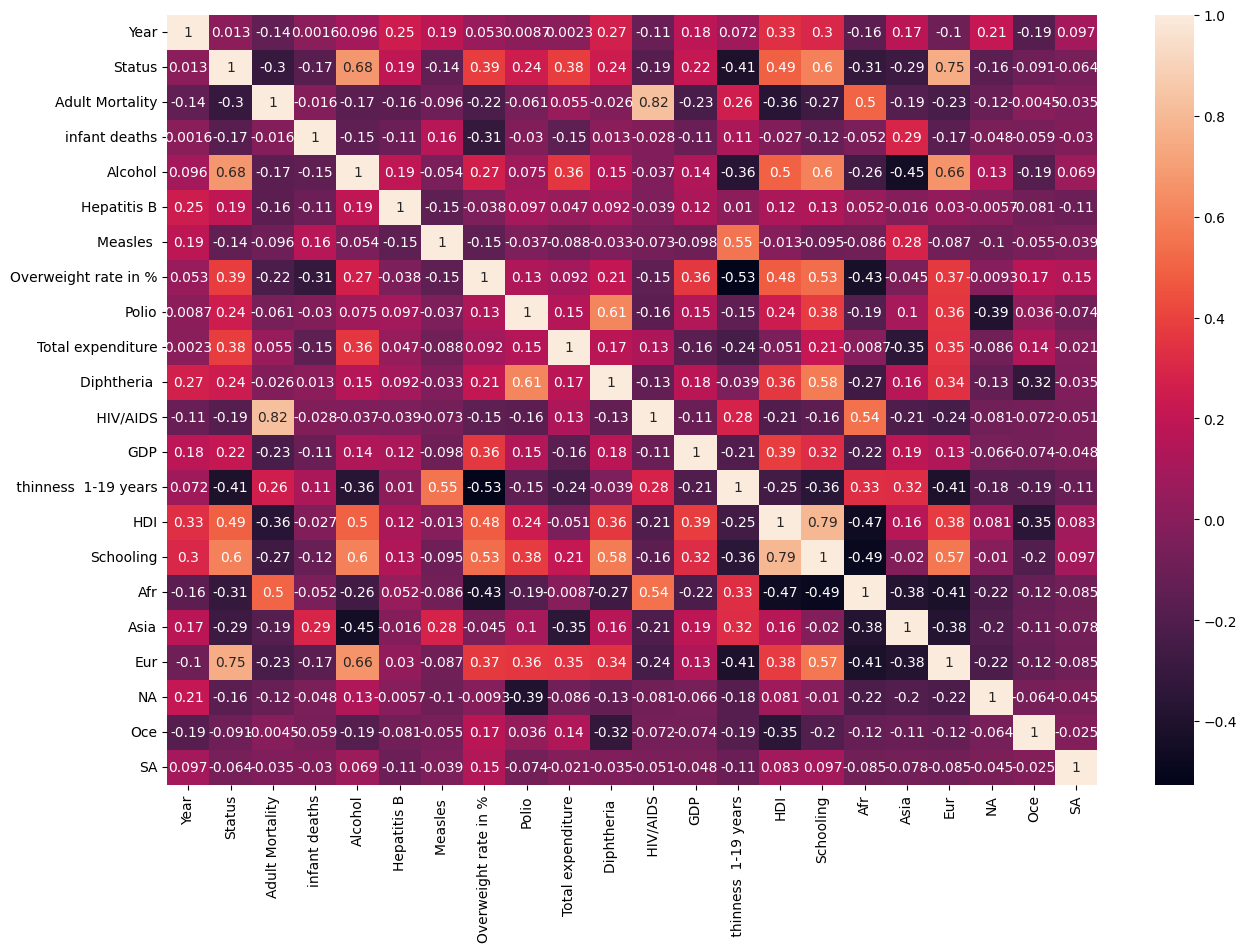

In [35]:
corr_matrix = Xtrain.corr()
plt.figure(figsize=(15,10))
sns.heatmap(corr_matrix, annot=True)
plt.show()

In [36]:
Xtrain.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 58 entries, 777 to 862
Data columns (total 22 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Year                   58 non-null     int64  
 1   Status                 58 non-null     int64  
 2   Adult Mortality        58 non-null     float64
 3   infant deaths          58 non-null     float64
 4   Alcohol                58 non-null     float64
 5   Hepatitis B            58 non-null     float64
 6   Measles                58 non-null     int64  
 7   Overweight rate in %   58 non-null     float64
 8   Polio                  58 non-null     float64
 9   Total expenditure      58 non-null     float64
 10  Diphtheria             58 non-null     float64
 11   HIV/AIDS              58 non-null     float64
 12  GDP                    58 non-null     float64
 13   thinness  1-19 years  58 non-null     float64
 14  HDI                    58 non-null     float64
 15  Schoo

Fill in any missing values with -1 just in case there are some left

In [37]:
Xtrain = Xtrain.replace(np.nan,-1)
Xval = Xval.replace(np.nan,-1)
Xtest = Xtest.replace(np.nan,-1)

<b> Training Phase </b>

In [38]:
Xval

,Year,Status,Adult Mortality,infant deaths,Alcohol,Hepatitis B,Measles,Overweight rate in %,Polio,Total expenditure,...,GDP,thinness 1-19 years,HDI,Schooling,Afr,Asia,Eur,NA,Oce,SA
2573,2011,0,155.0,10.0,6.07,98.0,3156,29.0,99.0,4.12,...,5491.16,8.1,0.72,13.3,0,1,0,0,0,0
511,2000,0,82.0,2.0,7.60,92.0,206,57.8,88.0,8.67,...,24124.17,0.5,0.86,15.9,0,0,0,1,0,0
1951,2006,0,179.0,6.0,0.03,78.0,7641,19.5,77.0,3.40,...,873.77,21.0,0.50,6.5,0,1,0,0,0,0
2703,2009,0,215.0,6.0,2.35,97.0,0,43.4,97.0,1.88,...,436.46,3.2,0.00,10.5,0,1,0,0,0,0
2088,2014,0,66.0,1.0,0.01,99.0,442,31.2,99.0,7.37,...,1233.80,1.5,0.66,12.4,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1426,2015,0,194.0,8.0,4.13,89.0,56,21.7,89.0,5.50,...,1233.80,8.8,0.58,10.8,0,1,0,0,0,0
607,2000,0,272.0,1.0,0.09,92.0,0,17.3,7.0,3.56,...,375.85,7.9,0.00,8.2,1,0,0,0,0,0
2330,2014,1,113.0,6.0,10.60,97.0,0,58.4,97.0,8.50,...,1233.80,1.2,0.84,15.1,0,0,1,0,0,0
990,2003,0,132.0,1.0,3.36,48.0,216,47.5,74.0,8.49,...,928.18,2.9,0.68,11.8,0,0,1,0,0,0


In [39]:
yval

2573    74.1
511     79.1
1951    64.2
2703    65.6
2088    82.0
        ... 
1426    65.7
607     59.5
2330    76.4
990     72.7
1233    73.0
Name: Life expectancy , Length: 2009, dtype: float64

<b>Linear regression</b>

[ 2.37839635e-01  4.44542713e+00 -1.42171981e-02 -9.36631574e-03
 -6.47384929e-01  2.63655200e-02  3.51221002e-05 -5.84840645e-02
  4.58796198e-02 -8.00405537e-01  8.74706828e-03 -1.41421698e-01
  4.75088784e-05 -2.40493525e-01  1.43289501e+00  1.55595612e+00
 -6.76299180e+00 -1.94908817e+00  1.73100804e+00  3.46043494e+00
  1.15308994e+00  2.36754704e+00]
-420.58180072702163


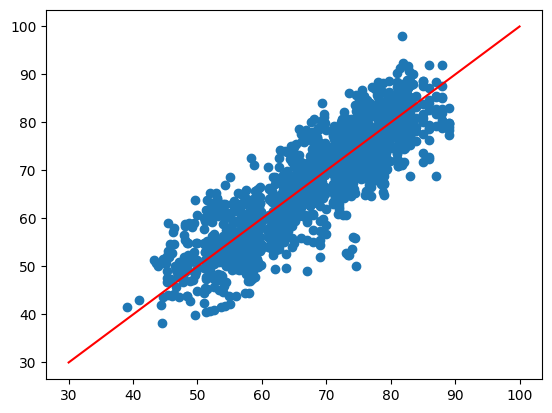

Validation RMSE: 5.103506502291439
Validation MAE: 3.9698811586


In [40]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

# Scaler makes no difference 
# scaler_linear = StandardScaler().fit(Xtrain)

# Xtrain_sc = scaler_linear.transform(Xtrain)
# Xval_sc = scaler_linear.transform(Xval)
# Xtest_sc = scaler_linear.transform(Xtest)

#Fit model
clf_linear = LinearRegression()
clf_linear.fit(Xtrain,ytrain)

print(clf_linear.coef_)
print(clf_linear.intercept_)

#Predict
Yth = clf_linear.predict(Xval)
plt.scatter(yval, Yth)
plt.plot([30,100], [30,100], 'r')
plt.show()

print('Validation RMSE:', np.sqrt(mean_squared_error(np.array(yval), Yth)))

MAE_val_linear = mean_absolute_error(yval, clf_linear.predict(Xval))
print(f'Validation MAE: {MAE_val_linear:.10f}')

<b>Ridge regression</b>

Without normalisation for curiosity

In [41]:
from sklearn.linear_model import Ridge
from scipy import optimize


def get_opt_ridge_model(Xtrain, Xval):
    def ridgemodel_eval(alpha):
        clf = Ridge(alpha=alpha)
        clf.fit(Xtrain, ytrain)
        return mean_squared_error(yval, clf.predict(Xval), squared = False)

    alphas = np.linspace(1,300,150)
    alphas_res = [ridgemodel_eval(alpha) for alpha in alphas]
    plt.plot(alphas, alphas_res, '.')
    plt.show()

    # Find Ridge alpha automatically
    opt_alpha = optimize.minimize_scalar(ridgemodel_eval, options = {'maxiter': 30}, method = 'bounded', bounds=(0.1, 400))
    print('Optimal alpha', opt_alpha)
    print("\n")

    clf_opt_ridge = Ridge(alpha = opt_alpha.x)
    clf_opt_ridge.fit(Xtrain, ytrain)
    return clf_opt_ridge


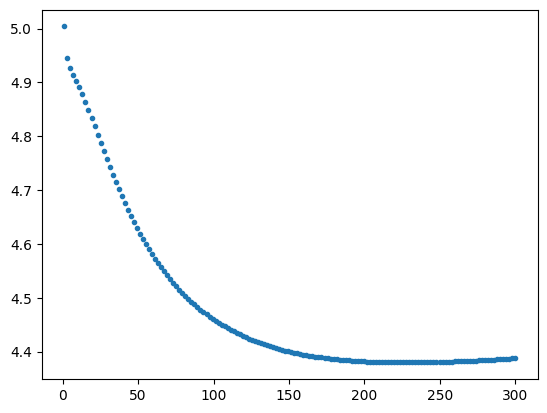

Optimal alpha      fun: 4.379752825873577
 message: 'Solution found.'
    nfev: 21
     nit: 21
  status: 0
 success: True
       x: 227.85123683105166


w_hat_ridge: -496.4204 [ 2.76405572e-01  7.03083002e-02 -2.66293366e-02  3.56897106e-04
  1.03193380e-01 -1.34427681e-02  6.00124791e-06  3.95608211e-02
  4.92925538e-02 -3.52932736e-01  6.75068093e-02 -2.38327675e-01
  5.44346885e-05 -2.36555092e-01  4.65467413e-02  6.88601312e-01
 -2.12241886e-01  4.38464084e-02  7.87722972e-02  7.70121203e-02
  1.10404535e-02  1.57060670e-03]
Validation RMSE: 4.37975
Validation MAE: 3.3288178072


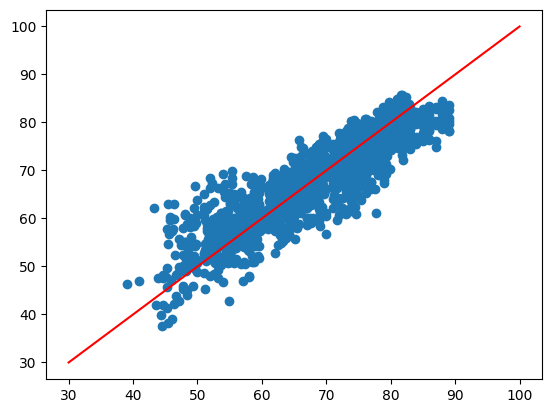

In [42]:
clf_opt_ridge = get_opt_ridge_model(Xtrain, Xval)

print(f"w_hat_ridge: {clf_opt_ridge.intercept_:.4f}", clf_opt_ridge.coef_)

plt.scatter(yval, clf_opt_ridge.predict(Xval))
plt.plot([30,100], [30,100], 'r')

RMSE_val_opt_ridge = mean_squared_error(yval, clf_opt_ridge.predict(Xval), squared = False)
print(f'Validation RMSE: {RMSE_val_opt_ridge:.5f}')

MAE_val_ridge = mean_absolute_error(yval, clf_opt_ridge.predict(Xval))
print(f'Validation MAE: {MAE_val_ridge:.10f}')

plt.show()

With normalisation

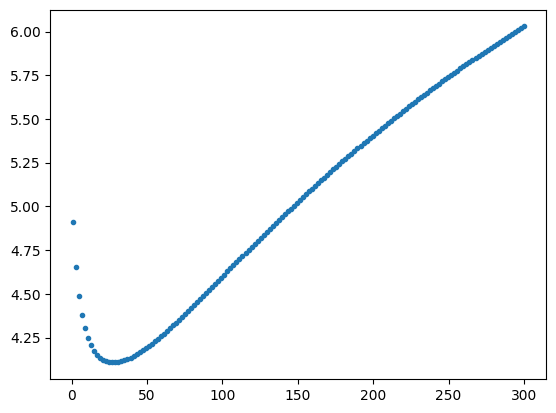

Optimal alpha      fun: 4.107041994496977
 message: 'Solution found.'
    nfev: 14
     nit: 14
  status: 0
 success: True
       x: 27.730500605275854


Validation RMSE: 4.10704
Validation MAE: 3.1971074820


In [43]:
scaler = StandardScaler().fit(Xtrain)

Xtrain_sc = scaler.transform(Xtrain)
Xval_sc = scaler.transform(Xval)
Xtest_sc = scaler.transform(Xtest)

clf_opt_ridge = get_opt_ridge_model(Xtrain_sc, Xval_sc)
RMSE_val_opt_ridge = mean_squared_error(yval, clf_opt_ridge.predict(Xval_sc), squared = False)
print(f'Validation RMSE: {RMSE_val_opt_ridge:.5f}')

MAE_val_ridge2 = mean_absolute_error(yval, clf_opt_ridge.predict(Xval_sc))
print(f'Validation MAE: {MAE_val_ridge2:.10f}')


<b>Decision tree for regression</b>

We found the best depth 3 with validation RMSE 4.8248.


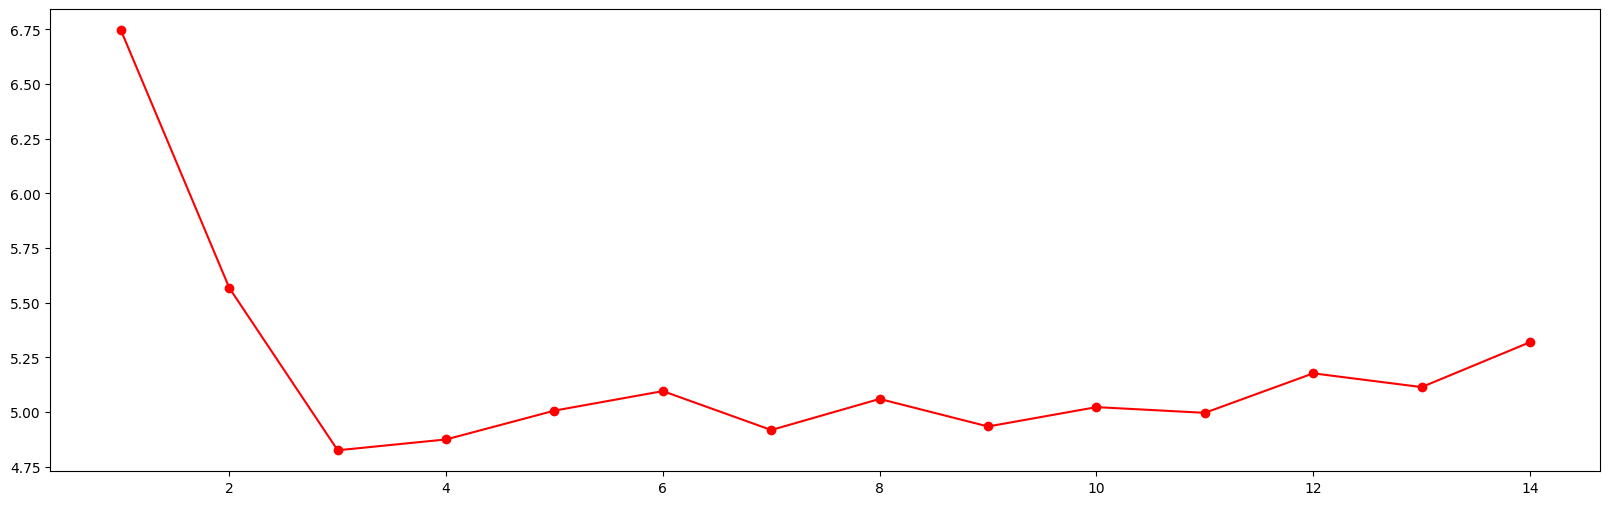

In [44]:
from sklearn.tree import DecisionTreeRegressor

depths = range(1,15)

val_metric = []
for depth in depths:
    clf = DecisionTreeRegressor(max_depth = depth).fit(Xtrain, ytrain)
    val_metric.append(mean_squared_error(yval, clf.predict(Xval), squared = False))

plt.figure(figsize=(20,6))
plt.plot(depths, val_metric,'or-') 


best_depth = depths[np.argmin(val_metric)]
print(f"We found the best depth {best_depth} with validation RMSE {min(val_metric):.4f}.")

clf_tree = DecisionTreeRegressor(max_depth = best_depth).fit(Xtrain, ytrain)

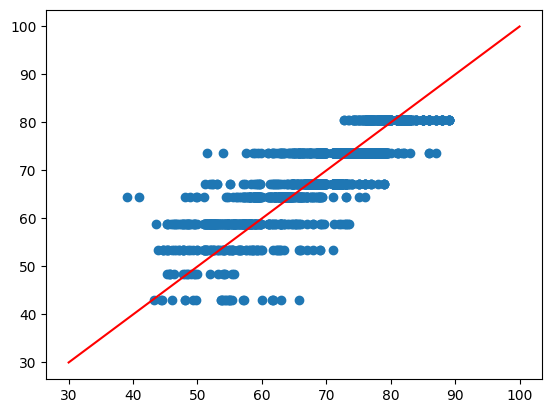

In [45]:
plt.scatter(yval, clf_tree.predict(Xval))
plt.plot([30,100], [30,100], 'r')

Likely quite overfitted, but still with a good validation result

In [46]:
train_rmse_tree = mean_squared_error(ytrain, clf_tree.predict(Xtrain), squared = False)
valid_rmse_tree = mean_squared_error(yval, clf_tree.predict(Xval), squared = False)
print(f"Train RMSE: {train_rmse_tree:.4f}")
print(f"Validation RMSE: {valid_rmse_tree:.4f}")

MAE_val_tree = mean_absolute_error(yval, clf_tree.predict(Xval))
print(f'Validation MAE: {MAE_val_tree:.5f}')

Train RMSE: 2.6486
Validation RMSE: 4.8248
Validation MAE: 3.43052


<b>Test set results</b>

Ridge Regression had very slightly better RMSE in validation and testing RMSE is not far off either 
Decision tree has somehow a lot better result than anything else

In [47]:
RMSE_test_opt_ridge = mean_squared_error(ytest, clf_opt_ridge.predict(Xtest_sc), squared = False)
print(f'RMSE Ridge Regression(test): {RMSE_test_opt_ridge:.5f}')

MAE_test_opt_ridge = mean_absolute_error(ytest, clf_opt_ridge.predict(Xtest_sc))
print(f'Validation MAE: {MAE_test_opt_ridge:.5f}')

test_rmse_tree = mean_squared_error(ytest, clf_tree.predict(Xtest), squared = False)
print(f"RMSE Decision tree(test): {test_rmse_tree:.5f}")

MAE_test_tree = mean_absolute_error(ytest, clf_tree.predict(Xtest))
print(f'Validation MAE: {MAE_test_tree:.5f}')

RMSE Ridge Regression(test): 4.30528
Validation MAE: 3.29975
RMSE Decision tree(test): 4.79646
Validation MAE: 3.39553


<a style='text-decoration:none;line-height:16px;display:flex;color:#5B5B62;padding:10px;justify-content:end;' href='https://deepnote.com?utm_source=created-in-deepnote-cell&projectId=92292694-234e-428c-b204-688d49a524de' target="_blank">
 </img>
Created in <span style='font-weight:600;margin-left:4px;'>Deepnote</span></a>